[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch07-concepts_workbook.ipynb)

# Two paths, one nucleus and one reference

After `The president of France` a model gives `is` 0.35 and `Emmanuel` 0.25.
After `is` its best token has 0.40, and after `Emmanuel` the token `Macron`
has 0.90. Greedy decoding writes `is`: does it write the more probable pair?
How does a count of shared words score `The cat on the mat` against
`The cat is on the mat`?

In [1]:
#@title Setup: run this cell first
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

REFERENCE = "The cat is on the mat"
# The lecture's beam tree: the step log-probability of each word after its prefix.
TREE = {("the",): {"cat": -0.4, "dog": -1.5, "old": -1.8}, ("a",): {"big": -0.2, "new": -1.3, "red": -1.6},
        ("one",): {"small": -0.1, "day": -0.9, "fine": -1.4}, ("the", "cat"): {"sat": -0.2, "ran": -1.1},
        ("a", "big"): {"house": -0.3, "tree": -0.8}, ("one", "small"): {"step": -0.1, "bird": -0.9}}
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def numbers(name, x, n, lo, hi):  # a setting typed in a cell: a list of n numbers from lo to hi
    if not (isinstance(x, (list, tuple)) and len(x) == n and all(type(v) in (int, float) and lo <= v <= hi for v in x)):
        raise Refused(f"{name} is {x!r}: {name} takes a list of {n} numbers from {lo} to {hi}.")
    return np.array(x, dtype=float)


def one(name, x, lo, hi, kind=(int, float)):  # one number typed in a cell
    if type(x) not in kind or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes {'a whole number' if kind == (int,) else 'a number'} from {lo} to {hi}.")
    return x


def bars(title, labels, values, xlabel, colors):  # one chart of labelled horizontal bars
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=colors)
    ax.bar_label(b, fmt="%.3f", padding=2, fontsize=8)
    lo, hi = min(0, *values), max(0, *values)
    span = (hi - lo) or 1  # all bars at 0 still get an axis
    ax.set(title=title, xlabel=xlabel, xlim=(lo - 0.3 * span if lo < 0 else 0, hi + 0.3 * span if hi > 0 else int(lo == 0)),
           ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: greedy decoding against the more probable pair.
def two_paths(probs):
    a, b, c, d = numbers("PROBS", probs, 4, 0, 1)
    greedy = "is" if a >= c else "Emmanuel"
    print(f"greedy writes {greedy}; is and its best token {a:.2f} × {b:.2f} = {a * b:.3f}; "
          f"Emmanuel Macron {c:.2f} × {d:.2f} = {c * d:.3f}")
    pairs = {"is + best token": a * b, "Emmanuel Macron": c * d}
    bars("probability of each two-token path", list(pairs), list(pairs.values()), "probability",
         ["C3" if k.startswith(greedy) else "C0" for k in pairs])


# Step 2: a temperature, then the top-k set and the nucleus.
def cut(p_typed, k, top_p, tau):
    p = numbers("P", p_typed, 6, 0, 1)
    if abs(p.sum() - 1) > 0.01:
        raise Refused(f"P is {p_typed!r}: P takes six probabilities that add up to 1.")
    k, top_p, tau = one("K", k, 1, 6, (int,)), one("TOP_P", top_p, 0.05, 1), one("TAU", tau, 0, 5)
    q = np.sort(p)[::-1]
    q = (q == q[0]) / (q == q[0]).sum() if tau == 0 else q ** (1 / tau) / (q ** (1 / tau)).sum()
    size = int(np.argmax(np.round(np.cumsum(q), 9) >= top_p)) + 1
    print(f"after TAU {tau}: {', '.join(f'{v:.3f}' for v in q)}; top-{k} keeps {q[:k].sum():.3f}; "
          f"the nucleus at {top_p} holds {size} token{'s' * (size > 1)}")
    bars(f"rank by rank after TAU {tau}; red: the nucleus", [f"rank {j + 1}" for j in range(6)], list(q), "probability",
         ["C3" if j < size else "0.7" for j in range(6)])


# Step 3: clipped n-gram precisions, the brevity penalty, BLEU and ROUGE-1.
def precision(cand, ref, n):  # matches, clipped by the reference's counts, and the candidate's n-grams
    c = Counter(tuple(cand[i:i + n]) for i in range(len(cand) - n + 1))
    r = Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
    return sum(min(v, r[g]) for g, v in c.items()), sum(c.values())


def scores(candidate):
    if not isinstance(candidate, str) or not candidate.split():
        raise Refused(f"CANDIDATE is {candidate!r}: CANDIDATE takes a sentence in quotes, words separated by spaces.")
    c, r = candidate.lower().split(), REFERENCE.lower().split()  # case ignored, as the lecture counts
    rows = [precision(c, r, n) for n in range(1, 5)]
    bp = min(1.0, math.exp(1 - len(r) / len(c)))
    p = [m / t if m else 1 / (2 ** k * t) for (m, t), k in zip(rows, np.cumsum([m == 0 for m, _ in rows])) if t]  # the k-th order with no match: 1/(2^k × its n-grams)
    bleu = 100 * bp * math.exp(np.mean(np.log(p))) if rows[0][0] else 0.0  # sacrebleu's sentence BLEU, case ignored, as the lecture scores
    rouge = sum(min(v, Counter(c)[w]) for w, v in Counter(r).items()) / len(r)
    print("; ".join(f"p{n} {m}/{t}" for n, (m, t) in enumerate(rows, 1)) + f"; brevity penalty {bp:.3f}; "
          f"BLEU {bleu:.1f}; ROUGE-1 {rouge:.3f}")
    bars("clipped precisions and ROUGE-1", ["p1", "p2", "p3", "p4", "ROUGE-1"],
         [m / t if t else 0.0 for m, t in rows] + [rouge], "share", ["C0"] * 4 + ["C3"])


# Appendix: beam search of width 1 to 3 over the lecture's tree.
def beam(width, root):
    width = one("WIDTH", width, 1, 3, (int,))
    if not isinstance(root, dict) or sorted(root) != ["a", "one", "the"]:
        raise Refused(f"ROOT is {root!r}: ROOT takes a log-probability for each of the, a and one.")
    hyps = [((w,), one(f"ROOT['{w}']", s, -5, 0)) for w, s in root.items()]
    for step in range(3):  # a hypothesis the tree does not extend is kept as it stands
        hyps = sorted(hyps, key=lambda h: -h[1])[:width]
        print(f"step {step + 1}: " + " | ".join(f"{' '.join(h)} {s:.2f}" for h, s in hyps))
        if step < 2:
            hyps = [(h + (w,), s + lp) for h, s in hyps for w, lp in TREE.get(h, {}).items()] + [x for x in hyps if x[0] not in TREE]
    bars(f"the {width} kept after three steps", [" ".join(h) for h, _ in hyps], [s for _, s in hyps],
         "summed log-probability", ["C3"] + ["C0"] * (len(hyps) - 1))


display(Markdown(f"The reference: `{REFERENCE}`. The beam tree holds {sum(len(v) for v in TREE.values())} edges "
                 "below its three root words."))

The reference: `The cat is on the mat`. The beam tree holds 15 edges below its three root words.

## 1. Greedy decoding and the more probable pair

Greedy decoding writes the most probable token at every step and keeps it.
`PROBS` holds four probabilities: `is`, the best token after `is`,
`Emmanuel`, and `Macron` after `Emmanuel`. Run the cell: which pair is more
probable, and which does greedy write? Then set the second number to `0.70`.

greedy writes is; is and its best token 0.35 × 0.40 = 0.140; Emmanuel Macron 0.25 × 0.90 = 0.225


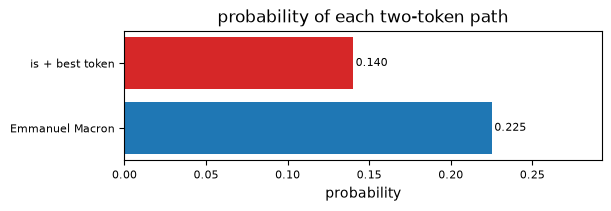

In [2]:
PROBS = [0.35, 0.40, 0.25, 0.90]  # is, best after is, Emmanuel, Macron after Emmanuel
two_paths(PROBS)

### Solution

In [3]:
display(Markdown(f"Greedy writes `is` and reaches {0.35 * 0.40:.3f}, while `Emmanuel Macron` has {0.25 * 0.90:.3f}: the "
                 f"more probable pair starts from the smaller first step. With 0.70 after `is`, greedy's pair has "
                 f"{0.35 * 0.70:.3f} and wins; it needs more than {0.225 / 0.35:.3f} after `is`."))

Greedy writes `is` and reaches 0.140, while `Emmanuel Macron` has 0.225: the more probable pair starts from the smaller first step. With 0.70 after `is`, greedy's pair has 0.245 and wins; it needs more than 0.643 after `is`.

## 2. Top-k, the nucleus and temperature

Top-k keeps the `K` most probable tokens; the nucleus keeps the smallest set
whose probabilities add up to at least `TOP_P`. A temperature `TAU` reshapes
the distribution first. Run the cell: how many tokens are in the nucleus?
Then set `TAU` to `0.5`, to `2` and to `0`.

after TAU 1: 0.400, 0.250, 0.150, 0.100, 0.060, 0.040; top-3 keeps 0.800; the nucleus at 0.9 holds 4 tokens


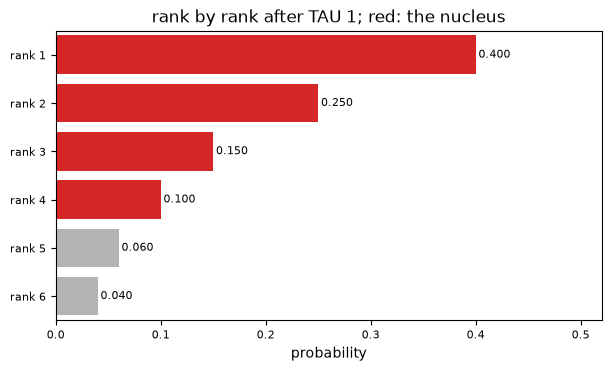

In [4]:
P = [0.40, 0.25, 0.15, 0.10, 0.06, 0.04]
K, TOP_P, TAU = 3, 0.9, 1
cut(P, K, TOP_P, TAU)

### Solution

In [5]:
P1 = np.array([0.40, 0.25, 0.15, 0.10, 0.06, 0.04])
size = {t: int(np.argmax(np.round(np.cumsum(P1 ** (1 / t) / (P1 ** (1 / t)).sum()), 9) >= 0.9)) + 1 for t in (0.5, 1, 2)}
display(Markdown(f"At `TAU` 1 top-3 keeps {P1[:3].sum():.2f} and the nucleus holds {size[1]} tokens; at 0.5 it holds "
                 f"{size[0.5]}, and at 2 it holds {size[2]}. At 0 every probability goes to the top token, which is "
                 "greedy decoding, and the top-3 set stays the same at every `TAU`."))

At `TAU` 1 top-3 keeps 0.80 and the nucleus holds 4 tokens; at 0.5 it holds 3, and at 2 it holds 5. At 0 every probability goes to the top token, which is greedy decoding, and the top-3 set stays the same at every `TAU`.

## 3. BLEU and ROUGE-1 against one reference

BLEU counts how many of the candidate's word sequences the reference holds,
each at most as often as the reference does, case ignored; ROUGE-1 counts how many of the
reference's words the candidate holds. Run the cell: which word does
`The cat on the mat` miss? Then try `The cat is on the mat The cat is on the mat`
and `A feline rests upon the rug`.

p1 5/5; p2 3/4; p3 1/3; p4 0/2; brevity penalty 0.819; BLEU 40.9; ROUGE-1 0.833


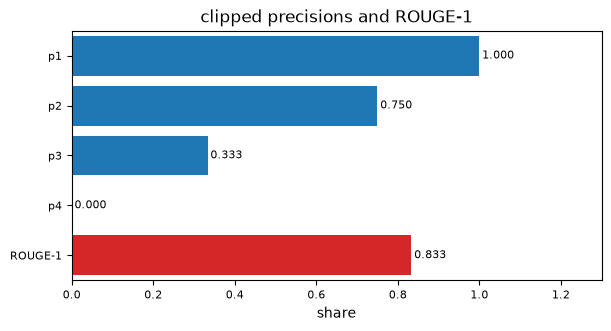

In [6]:
CANDIDATE = "The cat on the mat"
scores(CANDIDATE)

### Solution

In [7]:
ref = REFERENCE.split()
m, t = precision(ref[:2] + ref[3:], ref, 1)
display(Markdown(f"`The cat on the mat` misses `is`: its unigram precision is {m}/{t}, and ROUGE-1 is {5 / 6:.3f}, one reference "
                 f"word in six missing. The reference said twice reaches ROUGE-1 1.000, and the paraphrase a reader prefers "
                 f"shares one word, ROUGE-1 {1 / 6:.3f}."))

`The cat on the mat` misses `is`: its unigram precision is 5/5, and ROUGE-1 is 0.833, one reference word in six missing. The reference said twice reaches ROUGE-1 1.000, and the paraphrase a reader prefers shares one word, ROUGE-1 0.167.

## Appendix. Beam search and the formulas

The formulas behind the three steps:

probability of a path = the product of its step probabilities

temperature: raise every probability to the power 1/TAU, then divide by the sum

BLEU = brevity penalty × the geometric mean of the clipped precisions p1 to p4, with brevity penalty = e to the power 1 − r/c for a candidate shorter than the reference; as in the lecture's sentence BLEU, the k-th precision that is 0 counts 1 / (2 to the power k × the candidate's n-grams of that order)

ROUGE-1 = reference words found in the candidate / reference words

Beam search keeps the `WIDTH` best partial sequences by summed
log-probability, and width 1 is greedy decoding. `ROOT` holds the first
step's log-probabilities; the chart shows the hypotheses kept after three
steps.

step 1: the -0.30 | a -0.70 | one -1.20
step 2: the cat -0.70 | a big -0.90 | one small -1.30
step 3: the cat sat -0.90 | a big house -1.20 | one small step -1.40


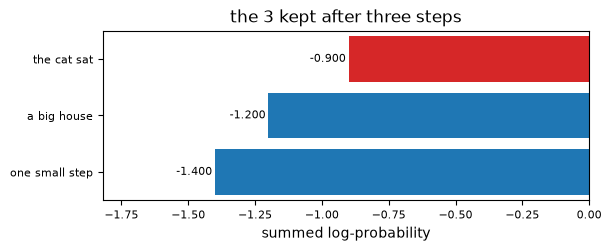

In [8]:
beam(3, {"the": -0.3, "a": -0.7, "one": -1.2})

**Exercise.** Raise the root edge to `a` from `-0.7` to `-0.35` and rerun the
cell at `WIDTH` 3 and at `WIDTH` 1. Which sentence does each return?

step 1: the -0.30 | a -0.70 | one -1.20
step 2: the cat -0.70 | a big -0.90 | one small -1.30
step 3: the cat sat -0.90 | a big house -1.20 | one small step -1.40


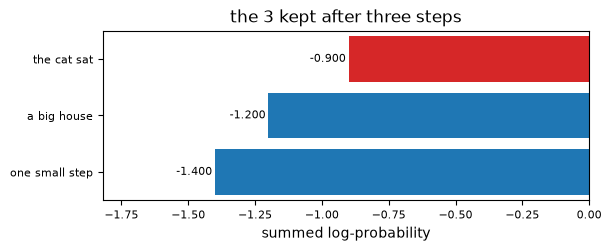

In [9]:
WIDTH, ROOT = 3, {"the": -0.3, "a": -0.7, "one": -1.2}
beam(WIDTH, ROOT)

### Solution

In [10]:
display(Markdown(f"At `WIDTH` 3, `a big house` wins at {-0.35 - 0.2 - 0.3:.2f} over `the cat sat` at {-0.3 - 0.4 - 0.2:.2f}. "
                 "At `WIDTH` 1, greedy keeps `the` at the first step and returns `the cat sat`."))

At `WIDTH` 3, `a big house` wins at -0.85 over `the cat sat` at -0.90. At `WIDTH` 1, greedy keeps `the` at the first step and returns `the cat sat`.